# Domino's Pizza Consulting (SI 485): Texas Census Data Pipeline

**Data:** U.S. Census Bureau, American Community Survey (ACS) 5-Year Estimates, 2024 (survey responses collected 2020 through 2024)

This notebook is a **data pipeline**. Each stage feeds the next one:

```
0. SETTINGS  ->  1. EXTRACT  ->  2. TRANSFORM  ->  3. ANALYZE  ->  4. OUTPUT
 (what to       (pull from      (clean, %MoE,     (summaries,     (heat maps,
  pull)          Census API)     apply MoE rules)  data loss)      saved files)
```

**To run it for a different state or add a variable, you only change the Settings cell.** Everything after it runs the same way.

Same structure as the New York notebook. Texas-specific changes:
- Texas has **254 counties** (the most of any state) and thousands of tracts, so the tract maps zoom in on **four metro areas** instead of one city: Houston, Dallas, San Antonio and Austin.
- The data-loss table (3d) shows how much of **each metro's population** a cutoff would throw away.

**Run it in Google Colab (nothing to install):**
1. Upload this notebook to https://colab.research.google.com
2. Click the **key icon** on the left > **Add new secret** > name it `CENSUS_API_KEY`, paste your Census key, and turn on **Notebook access**
3. **Runtime > Run all**

**Run it in Jupyter on your computer:** the key is read from your `.env` file (see Settings). You need `pip install requests pandas plotly geopandas matplotlib kaleido`.

In [18]:
import requests                    # lets us download data from the internet
import pandas as pd                # lets us work with data in tables
import plotly.express as px        # draws the interactive county maps
import geopandas as gpd            # reads map shapes (for the tract maps)
import matplotlib.pyplot as plt    # draws the tract maps
from matplotlib.patches import Patch   # lets us build a color key (legend) by hand

## 0. Settings (the only cell you need to change)

**To pull an additional column:** add one line to `VARIABLES` with the Census code and a short name. The pipeline pulls both its estimate (E) and its margin of error (M) automatically. To also draw it as a heat map, add it to `MAP_COLORS`.

Look up codes at https://api.census.gov/data/2024/acs/acs5/variables.html

In [19]:
import os

# are we running in Google Colab? (True in Colab, False in Jupyter on a computer)
try:
    from google.colab import userdata           # this line only works inside Google Colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# my Census API key
if IN_COLAB:
    API_KEY = userdata.get("CENSUS_API_KEY")    # in Colab: read it from Secrets (the key icon on the left)
else:
    # on a computer: read it from the .env file (keep .env out of GitHub!)
    ENV_FILE = "/Users/jessicamoon/Desktop/SI485/.env"
    if "CENSUS_API_KEY" not in os.environ and os.path.exists(ENV_FILE):
        with open(ENV_FILE) as f:
            for line in f:
                if line.startswith("CENSUS_API_KEY="):
                    os.environ["CENSUS_API_KEY"] = line.strip().split("=", 1)[1].strip('"\'')
    API_KEY = os.environ.get("CENSUS_API_KEY")
print("API key loaded:", bool(API_KEY))

# which state and which year of data
STATE_CODE = "48"            # Texas's 2-digit state code (FIPS code)
STATE_NAME = "Texas"
YEAR = "2024"                # the 2024 ACS 5-year data (covers 2020-2024; newest available)

# the Census variables to pull: "code": "short name"
# to pull another column, add a line here (leave "population" in, the pipeline uses it)
VARIABLES = {
    "B19013_001": "median_income",   # median household income (dollars)
    "B01002_001": "median_age",      # median age (years)
    "B01003_001": "population",      # total population (people)
}

# MARGIN OF ERROR RULES, using %MoE = MoE / Estimate x 100
# Starting values are the same as the New York notebook so the states are comparable.
# Look at the data-loss tables in 3d, then adjust these for Texas if needed.
# counties: reject a value if its %MoE is above this number
COUNTY_REJECT_CUTOFF = {"median_income": 10, "median_age": 10}

# tracts: flag "caution" above the first number, "rejected" above the second
TRACT_CAUTION_CUTOFF = {"median_income": 30, "median_age": 15}
TRACT_REJECT_CUTOFF = {"median_income": 66, "median_age": 20}

# which variables to draw as heat maps, and the color for each
MAP_COLORS = {"median_income": "Greens", "median_age": "Blues", "population": "Purples"}

# the areas to show close up on the tract maps: "name": [county codes]
# Texas is too big for one close-up, so we zoom in on the 4 biggest metros (their core counties)
CLOSE_UPS = {
    "Houston (Harris Co.)": ["201"],
    "Dallas (Dallas Co.)": ["113"],
    "San Antonio (Bexar Co.)": ["029"],
    "Austin (Travis Co.)": ["453"],
}

# set to True to save the data (CSV) and county maps (HTML) on your computer
SAVE_FILES = False

API key loaded: True


## 1. Extract: pull the data from the Census API

One function does the pulling for **any** geography (counties or tracts). For every variable in `VARIABLES`, it asks for:
- the **estimate** (code ending in `E`)
- the **margin of error** (code ending in `M`). Census gives this as a **value** in the same units as the estimate (dollars, years, people), at the **90% confidence level**.

In [20]:
def pull_census(geography):
    # start the list of columns with the place name
    columns = ["NAME"]

    # add the estimate (E) and margin of error (M) for every variable in our settings
    for census_code in VARIABLES:
        columns.append(census_code + "E")
        columns.append(census_code + "M")

    # what we are asking the Census for
    params = {
        "get": ",".join(columns),          # the columns, separated by commas
        "for": geography,                  # e.g. "county:*" or "tract:*"
        "in": "state:" + STATE_CODE,       # only our state
        "key": API_KEY                     # our key
    }

    # the web address for the ACS 5-year data in our chosen year
    url = "https://api.census.gov/data/" + YEAR + "/acs/acs5"

    # send the request and turn the answer into a table (the first row is the column names)
    data = requests.get(url, params=params).json()
    table = pd.DataFrame(data[1:], columns=data[0])

    # rename the codes to short names, e.g. B19013_001E -> median_income, B19013_001M -> median_income_moe
    for census_code, name in VARIABLES.items():
        table = table.rename(columns={census_code + "E": name, census_code + "M": name + "_moe"})

    return table


# pull every county and every census tract in the state
counties = pull_census("county:*")
tracts = pull_census("tract:*")

print("Counties pulled:", len(counties))
print("Tracts pulled:", len(tracts))
tracts.head()

Counties pulled: 254
Tracts pulled: 6896


,NAME,median_income,median_income_moe,median_age,median_age_moe,population,population_moe,state,county,tract
0,Census Tract 9501; Anderson County; Texas,70938,14478,44.1,4.6,5345,662,48,001,950100
1,Census Tract 9504.01; Anderson County; Texas,117870,66326,40.2,1.7,4172,154,48,001,950401
2,Census Tract 9504.02; Anderson County; Texas,-666666666,-222222222,43.7,1.4,5153,105,48,001,950402
3,Census Tract 9505; Anderson County; Texas,59000,19477,38.0,6.8,4769,730,48,001,950500
4,Census Tract 9506; Anderson County; Texas,43039,14176,35.8,6.1,5874,709,48,001,950600


In [21]:
# download the county shapes (outline of every U.S. county) for the interactive county maps
county_shapes = requests.get("https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json").json()

# keep only our state's counties (their codes start with our state code) so the file stays small
state_shapes = []
for shape in county_shapes["features"]:
    if shape["id"].startswith(STATE_CODE):
        state_shapes.append(shape)
county_shapes["features"] = state_shapes

# download the census tract shapes for our state from the Census Bureau
tract_shapes = gpd.read_file("https://www2.census.gov/geo/tiger/GENZ" + YEAR + "/shp/cb_" + YEAR + "_" + STATE_CODE + "_tract_500k.zip")

print("County shapes:", len(county_shapes["features"]))
print("Tract shapes:", len(tract_shapes))

County shapes: 254
Tract shapes: 6884


## 2. Transform: clean the data and apply the margin of error rules

For every variable, the cleaning step:
1. Turns the text into numbers.
2. Treats **Census special codes** as missing. These are big negative numbers:
   - `-666666666` = no estimate (usually nobody lives there, like a park or airport)
   - `-222222222` = no MoE because there's no estimate
   - `-333333333` = the median is in the top or bottom bracket (income shows as `250001`, meaning "$250,000 or more"). **We keep the estimate**; only the MoE is unknown.
   - `-555555555` = the number is fixed by Census, so there's no sampling error
3. Works out **%MoE = MoE / Estimate x 100**.
4. Gives each value a **status**: `ok`, `caution`, `rejected`, `no data`, or `no MoE (kept)`.
5. Makes a `_final` column that only holds the values we trust. Rejected values become blank (they show up gray on the maps).

In [22]:
def get_status(estimate, pct_moe, caution, reject):
    if pd.isna(estimate):                           # Census gave no estimate
        return "no data"
    if pd.isna(pct_moe):                            # there is an estimate but no MoE (special code)
        return "no MoE (kept)"
    if reject is not None and pct_moe > reject:     # too uncertain: throw it out
        return "rejected"
    if caution is not None and pct_moe > caution:   # usable, but be careful
        return "caution"
    return "ok"


def clean(table, caution_cutoffs, reject_cutoffs):
    for name in VARIABLES.values():
        moe = name + "_moe"

        # turn text into numbers
        table[name] = pd.to_numeric(table[name])
        table[moe] = pd.to_numeric(table[moe])

        # special codes are negative numbers: keep only values of 0 or more (the rest become blank)
        table[name] = table[name].where(table[name] >= 0)
        table[moe] = table[moe].where(table[moe] >= 0)

        # %MoE = MoE / Estimate x 100 (only where the estimate is above 0, so we never divide by 0)
        table[name + "_pct_moe"] = (table[moe] / table[name] * 100).where(table[name] > 0)

        # give every row a status using our rules (variables with no rule get None = no cutoff)
        caution = caution_cutoffs.get(name)
        reject = reject_cutoffs.get(name)
        statuses = []
        for estimate, pct in zip(table[name], table[name + "_pct_moe"]):
            statuses.append(get_status(estimate, pct, caution, reject))
        table[name + "_status"] = statuses

        # the final value we use: blank out anything rejected
        table[name + "_final"] = table[name].where(table[name + "_status"] != "rejected")

    return table


# clean both tables (counties have no "caution" level, so we pass an empty {})
counties = clean(counties, {}, COUNTY_REJECT_CUTOFF)
tracts = clean(tracts, TRACT_CAUTION_CUTOFF, TRACT_REJECT_CUTOFF)

# make the ID codes the maps use to match rows to shapes
counties["fips"] = counties["state"] + counties["county"]                     # 5 digits: state + county
tracts["GEOID"] = tracts["state"] + tracts["county"] + tracts["tract"]        # 11 digits: state + county + tract

# remove the state name from the place names so they look cleaner
counties["NAME"] = counties["NAME"].str.replace(", " + STATE_NAME, "")

counties.head()

,NAME,median_income,median_income_moe,median_age,median_age_moe,population,population_moe,state,county,median_income_pct_moe,median_income_status,median_income_final,median_age_pct_moe,median_age_status,median_age_final,population_pct_moe,population_status,population_final,fips
0,Anderson County,62068,4521,39.7,0.4,58439,NaN,48,001,7.283947,ok,62068.0,1.007557,ok,39.7,NaN,no MoE (kept),58439,48001
1,Andrews County,72242,9282,33.0,0.6,18610,NaN,48,003,12.848481,rejected,NaN,1.818182,ok,33.0,NaN,no MoE (kept),18610,48003
2,Angelina County,60960,3197,37.8,0.5,87275,NaN,48,005,5.244423,ok,60960.0,1.322751,ok,37.8,NaN,no MoE (kept),87275,48005
3,Aransas County,69466,8686,49.9,0.9,24876,NaN,48,007,12.503959,rejected,NaN,1.803607,ok,49.9,NaN,no MoE (kept),24876,48007
4,Archer County,72159,8735,42.8,0.8,8867,NaN,48,009,12.105212,rejected,NaN,1.869159,ok,42.8,NaN,no MoE (kept),8867,48009


## 3. Analyze

### 3a. County summary
The average and middle value **across counties** (each county counts once, no matter its size), plus how big the margins of error are.

In [23]:
summary_rows = []
for name in MAP_COLORS:                       # the variables we map (income and age)
    summary_rows.append({
        "variable": name,
        "average across counties": round(counties[name].mean(), 1),
        "middle county (median)": round(counties[name].median(), 1),
        "average MoE (value)": round(counties[name + "_moe"].mean(), 2),      # blank = Census gives no MoE
        "average %MoE": round(counties[name + "_pct_moe"].mean(), 1),
        "largest %MoE": round(counties[name + "_pct_moe"].max(), 1),
        "counties rejected": (counties[name + "_status"] == "rejected").sum(),
    })

pd.DataFrame(summary_rows)

,variable,average across counties,middle county (median),average MoE (value),average %MoE,largest %MoE,counties rejected
0,median_income,66481.9,65034.5,8067.85,13.1,87.2,120
1,median_age,40.1,39.3,2.01,4.7,65.7,31
2,population,118852.1,18648.5,177.29,18.8,90.9,0


In [24]:
# the top 5 and bottom 5 counties for each variable, with their margins of error
for name in MAP_COLORS:
    columns_to_show = ["NAME", name, name + "_moe", name + "_pct_moe"]
    print("HIGHEST", name)
    print(counties.sort_values(name, ascending=False)[columns_to_show].head(5).round(1).to_string(index=False))
    print()
    print("LOWEST", name)
    print(counties.sort_values(name)[columns_to_show].head(5).round(1).to_string(index=False))
    print()

HIGHEST median_income
            NAME  median_income  median_income_moe  median_income_pct_moe
 Rockwall County         127981               4257                    3.3
   Collin County         121600               1883                    1.5
  Kendall County         114962               8014                    7.0
Fort Bend County         114041               1899                    1.7
   Denton County         111498               1485                    1.3

LOWEST median_income
          NAME  median_income  median_income_moe  median_income_pct_moe
Swisher County          36165              14512                   40.1
 Zavala County          36749               5834                   15.9
  Starr County          37639               4431                   11.8
 Dimmit County          38808               8956                   23.1
 Kenedy County          38882               4589                   11.8

HIGHEST median_age
          NAME  median_age  median_age_moe  median_age_pct_m

### 3b. Are two counties really different? (comparison rule)
Two estimates are only **significantly different** if the gap between them is bigger than their combined MoE:
**|A - B| > square root of (MoE_A squared + MoE_B squared)**

Here we test each county against the next one in the ranking.

In [25]:
for name in MAP_COLORS:
    ranked = counties.sort_values(name, ascending=False).reset_index()   # highest first
    print("Top 5 for", name)
    for i in range(5):
        a = ranked.loc[i]           # this county
        b = ranked.loc[i + 1]       # the next county down
        gap = a[name] - b[name]
        combined_moe = (a[name + "_moe"] ** 2 + b[name + "_moe"] ** 2) ** 0.5
        if pd.isna(combined_moe):                   # Census gave no MoE (e.g. county population is a fixed count)
            verdict = "no MoE, so the count is treated as exact"
        elif gap > combined_moe:
            verdict = "really higher"
        else:
            verdict = "statistically TIED"
        print("  " + a["NAME"] + " vs " + b["NAME"] + ": gap " + str(round(gap, 1)) + ", combined MoE " + str(round(combined_moe, 1)) + " -> " + verdict)
    print()

Top 5 for median_income
  Rockwall County vs Collin County: gap 6381, combined MoE 4654.9 -> really higher
  Collin County vs Kendall County: gap 6638, combined MoE 8232.2 -> statistically TIED
  Kendall County vs Fort Bend County: gap 921, combined MoE 8235.9 -> statistically TIED
  Fort Bend County vs Denton County: gap 2543, combined MoE 2410.7 -> really higher
  Denton County vs Williamson County: gap 158, combined MoE 2169.1 -> statistically TIED

Top 5 for median_age
  Loving County vs Kent County: gap 26.2, combined MoE 17.8 -> really higher
  Kent County vs Terrell County: gap 0.1, combined MoE 6.2 -> statistically TIED
  Terrell County vs Real County: gap 0.4, combined MoE 6.8 -> statistically TIED
  Real County vs Menard County: gap 0.0, combined MoE 9.1 -> statistically TIED
  Menard County vs Jeff Davis County: gap 1.5, combined MoE 9.4 -> statistically TIED

Top 5 for population
  Harris County vs Dallas County: gap 2217124, combined MoE nan -> no MoE, so the count is trea

### 3c. Tract reliability
How many tracts fall into each status with our rules?

In [26]:
# count each status for each mapped variable
status_counts = {}
for name in MAP_COLORS:
    status_counts[name] = tracts[name + "_status"].value_counts()

pd.DataFrame(status_counts).fillna(0).astype(int)

,median_income,median_age,population
caution,1935,1211,0
no MoE (kept),42,0,62
no data,88,46,0
ok,4684,4342,6834
rejected,147,1297,0


### 3d. How much data does each %MoE cutoff throw away?
If we rejected every tract above a cutoff, what share of tracts and **people** would we lose, statewide and in each metro?

This matters for Domino's: if a rule throws out dense city neighborhoods more than other places, the analysis would leave out key delivery markets. One table per variable.

In [27]:
total_people = tracts["population"].sum()                              # everyone in the state
cutoffs_to_test = [5, 10, 15, 20, 25, 30, 40, 50, 66]

for name in MAP_COLORS:
    # a tract survives if its %MoE is under the cutoff, or it has an estimate but no MoE (kept)
    loss_rows = []
    for cutoff in cutoffs_to_test:
        survives = (tracts[name + "_pct_moe"] <= cutoff) | (tracts[name + "_status"] == "no MoE (kept)")
        row = {"%MoE cutoff": cutoff,
               "% tracts lost": round(100 - survives.mean() * 100, 1),
               "% people lost (state)": round(100 - tracts.loc[survives, "population"].sum() / total_people * 100, 1)}
        for metro, metro_counties in CLOSE_UPS.items():
            in_metro = tracts["county"].isin(metro_counties)
            metro_people = tracts.loc[in_metro, "population"].sum()
            row["% people lost: " + metro.split(" (")[0]] = round(100 - tracts.loc[survives & in_metro, "population"].sum() / metro_people * 100, 1)
        loss_rows.append(row)
    print("=== " + name + " ===")
    display(pd.DataFrame(loss_rows))

=== median_income ===


,%MoE cutoff,% tracts lost,% people lost (state),% people lost: Houston,% people lost: Dallas,% people lost: San Antonio,% people lost: Austin
0,5,98.5,98.5,97.8,97.9,99.4,98.4
1,10,91.6,90.0,90.3,89.3,89.6,89.8
2,15,76.9,73.0,78.9,74.2,68.2,67.4
3,20,59.5,54.8,62.4,56.8,46.9,54.9
4,25,44.0,38.9,47.3,43.8,30.0,36.0
5,30,31.5,26.4,35.2,29.9,19.3,22.4
6,40,15.5,12.0,17.7,13.3,7.5,11.2
7,50,8.0,5.7,8.3,6.3,2.7,5.7
8,66,3.4,2.0,2.5,1.7,0.5,1.1


=== median_age ===


,%MoE cutoff,% tracts lost,% people lost (state),% people lost: Houston,% people lost: Dallas,% people lost: San Antonio,% people lost: Austin
0,5,93.4,92.1,95.0,94.1,91.0,83.5
1,10,65.8,60.5,67.3,65.4,52.9,41.9
2,15,37.0,31.8,39.7,38.9,20.0,15.1
3,20,19.5,15.5,20.8,20.4,9.9,9.0
4,25,10.2,7.3,9.5,10.6,4.5,4.7
5,30,5.6,3.6,4.4,5.8,0.8,4.2
6,40,2.3,1.1,1.3,2.3,0.0,0.6
7,50,1.3,0.4,0.4,0.8,0.0,0.4
8,66,0.8,0.1,0.1,0.1,0.0,0.0


=== population ===


,%MoE cutoff,% tracts lost,% people lost (state),% people lost: Houston,% people lost: Dallas,% people lost: San Antonio,% people lost: Austin
0,5,98.2,98.9,99.6,99.6,99.9,99.3
1,10,90.0,87.6,95.2,94.5,85.3,88.9
2,15,55.0,48.8,66.9,60.9,46.5,45.3
3,20,22.3,18.5,31.5,24.9,12.6,19.8
4,25,9.1,7.2,14.1,11.4,3.4,9.5
5,30,4.0,3.0,6.0,5.3,1.2,4.3
6,40,0.8,0.5,0.9,1.2,0.4,0.9
7,50,0.2,0.1,0.2,0.6,0.0,0.0
8,66,0.0,0.0,0.0,0.0,0.0,0.0


## 4. Output: heat maps

### 4a. County heat maps
Each county is colored by its value. In Jupyter you can hover over a county to see its name and value; the picture underneath shows up on GitHub.

In [29]:
county_maps = {}    # we keep the maps here so we can save them at the end

for name, color in MAP_COLORS.items():
    county_map = px.choropleth(
        counties,                            # our county table
        geojson=county_shapes,               # the county shapes
        locations="fips",                    # the column that matches each row to a shape
        color=name + "_final",               # color by the value we trust
        color_continuous_scale=color,        # light = low, dark = high
        hover_name="NAME",                   # show the county name on hover
        hover_data={name + "_moe": True, name + "_pct_moe": ":.1f"},   # also show the MoE on hover
        labels={name + "_final": name},
        title=name + " by County, " + STATE_NAME + " (ACS " + YEAR + " 5-Year)"
    )
    county_map.update_geos(fitbounds="locations", visible=False)    # zoom in on our state

    if IN_COLAB:
        county_map.show()                        # Colab shows interactive maps its own way
    else:
        # "notebook_connected" loads the map tools from the internet, which keeps this file small enough for GitHub
        county_map.show("notebook_connected")
        # also show it as a plain picture so it is visible on GitHub (needs the kaleido add-on)
        # county_map.show("png", width=900, height=650)

    county_maps[name] = county_map

### 4b. Census tract heat maps
Each tract is colored by its value. **Gray tracts are rejected by our MoE rules or have no data.** The left side is the whole state; the right side zooms in on the four metros, because city tracts are too small to see on the state map. All five maps use the **same color scale**, so the same shade means the same value everywhere.

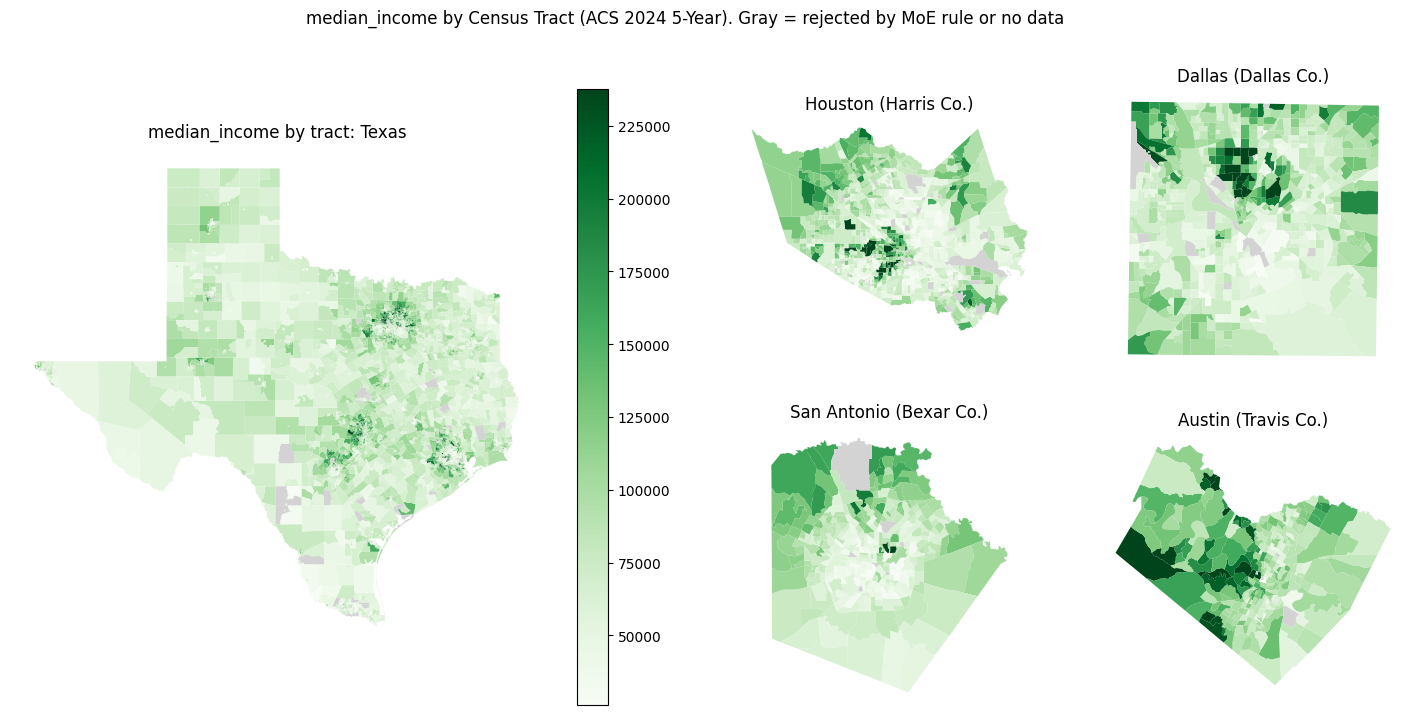

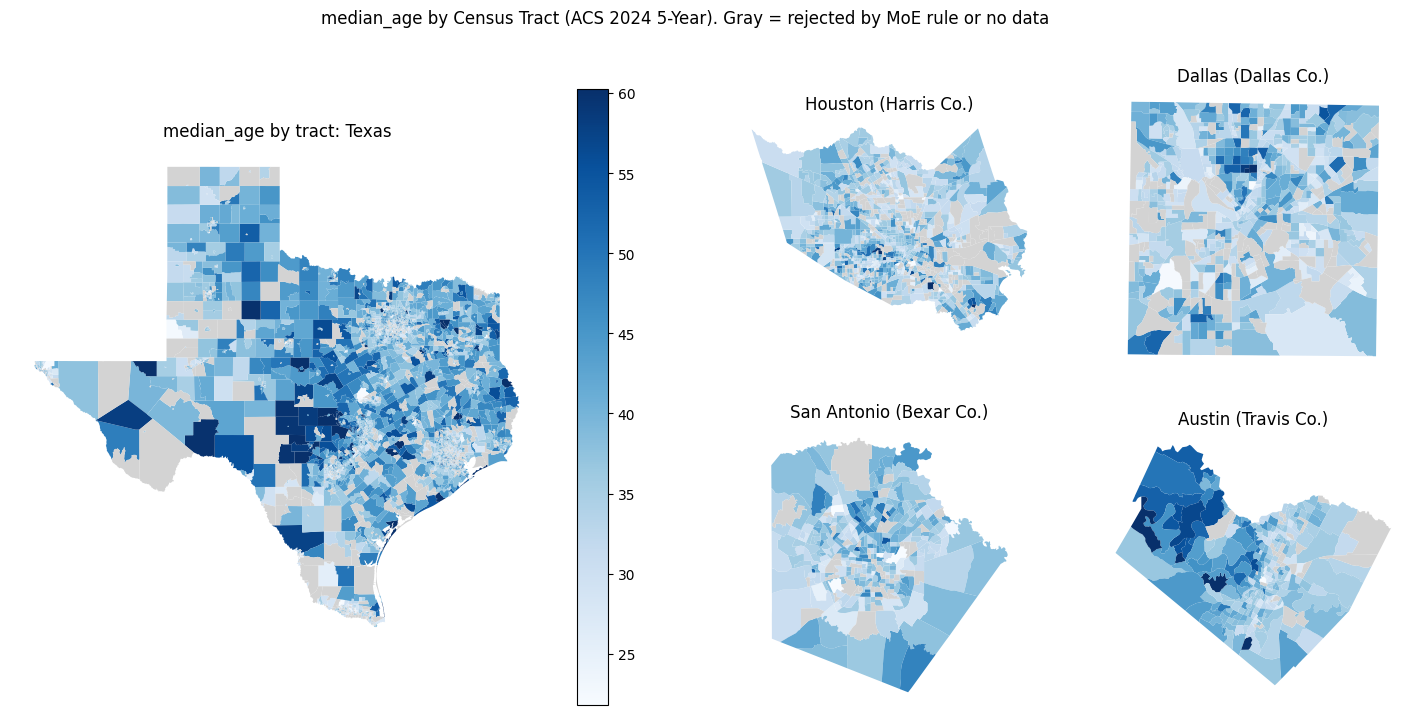

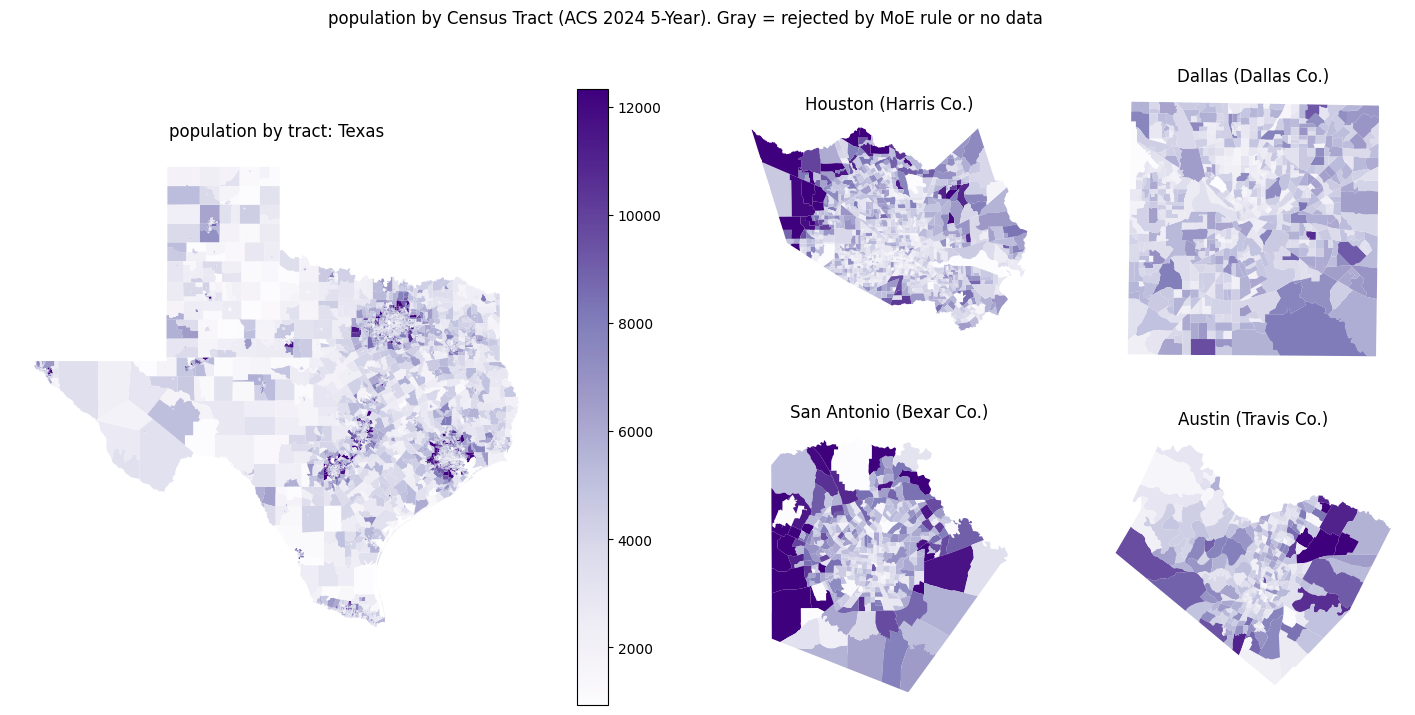

In [ ]:
# attach our tract data to the tract shapes, matching on the 11-digit GEOID
tract_map_data = tract_shapes.merge(tracts, on="GEOID", how="left")


def state_and_metros_figure():
    # layout: big state map on the left, the 4 metros in a 2x2 grid on the right
    fig = plt.figure(figsize=(18, 8))
    grid = fig.add_gridspec(2, 4)
    state_ax = fig.add_subplot(grid[:, :2])
    metro_axes = [fig.add_subplot(grid[r, 2 + c]) for r in range(2) for c in range(2)]
    return fig, state_ax, metro_axes


for name, color in MAP_COLORS.items():
    fig, state_ax, metro_axes = state_and_metros_figure()
    # one shared color scale (ignore the top/bottom 1% so a few extreme tracts don't wash out the colors)
    low, high = tract_map_data[name + "_final"].quantile([0.01, 0.99])

    tract_map_data.plot(column=name + "_final", cmap=color, vmin=low, vmax=high, legend=True,
                        ax=state_ax, missing_kwds={"color": "lightgrey"})
    state_ax.set_title(name + " by tract: " + STATE_NAME)
    state_ax.axis("off")

    for ax, (metro, metro_counties) in zip(metro_axes, CLOSE_UPS.items()):
        close_up = tract_map_data[tract_map_data["COUNTYFP"].isin(metro_counties)]
        close_up.plot(column=name + "_final", cmap=color, vmin=low, vmax=high,
                      ax=ax, missing_kwds={"color": "lightgrey"})
        ax.set_title(metro)
        ax.axis("off")

    fig.suptitle(name + " by Census Tract (ACS " + YEAR + " 5-Year). Gray = rejected by MoE rule or no data")
    plt.show()

### 4c. Reliability maps
Where is the data trustworthy? Each tract is colored by its **status** from our MoE rules.

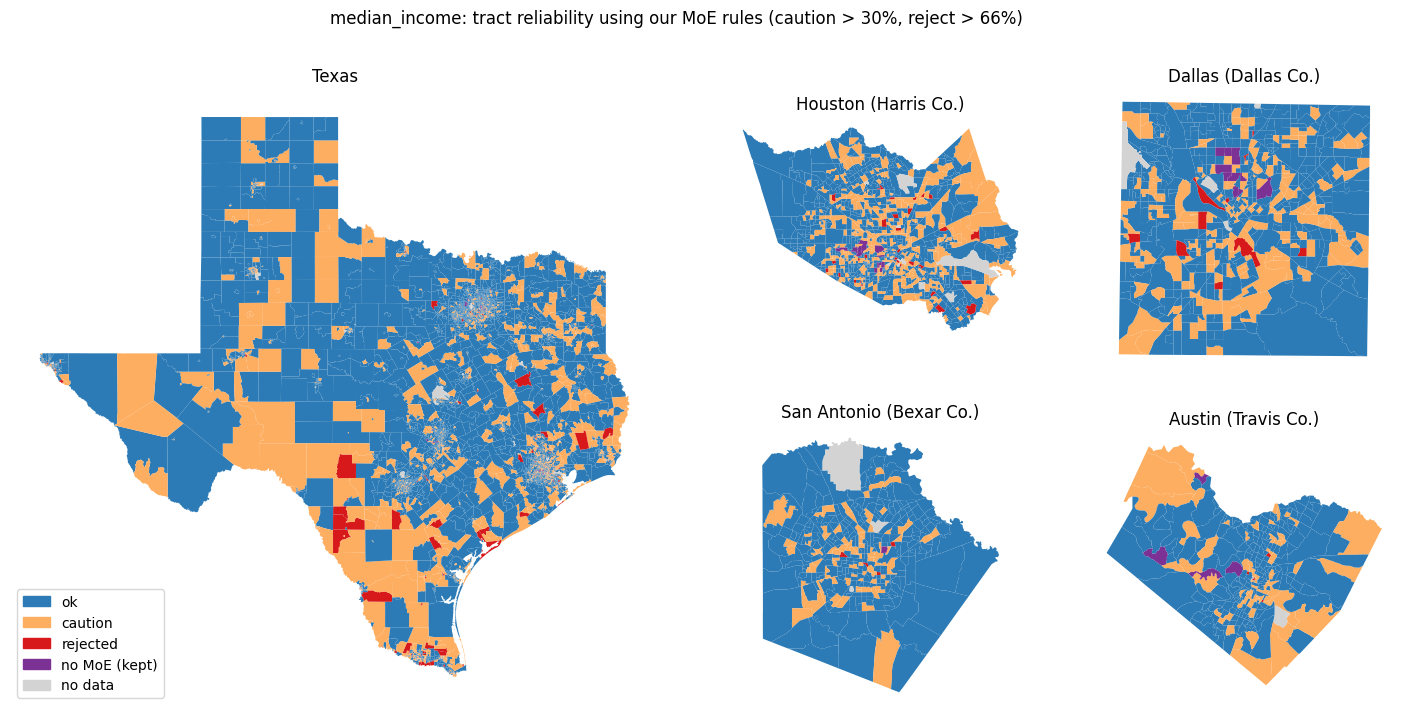

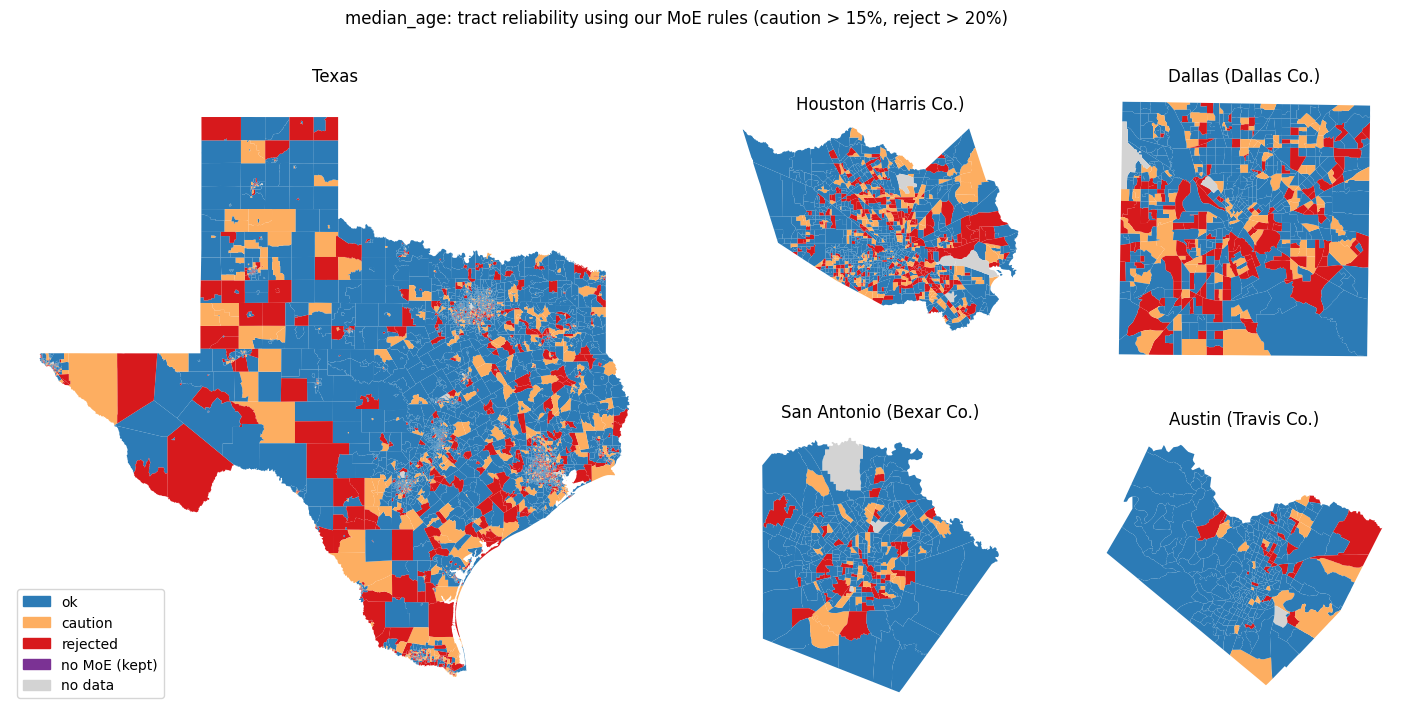

In [ ]:
# one color for each status
status_colors = {
    "ok": "#2c7bb6",              # blue
    "caution": "#fdae61",         # orange
    "rejected": "#d7191c",        # red
    "no MoE (kept)": "#7b3294",   # purple (e.g. income of $250,000+)
    "no data": "lightgrey",
}

for name in MAP_COLORS:
    # skip variables that have no MoE rule in Settings (every tract would just be "ok")
    if name not in TRACT_REJECT_CUTOFF:
        continue

    # look up the color for each tract's status (tracts with no match at all are gray)
    tract_map_data["status_color"] = tract_map_data[name + "_status"].map(status_colors).fillna("lightgrey")

    fig, state_ax, metro_axes = state_and_metros_figure()
    tract_map_data.plot(color=tract_map_data["status_color"], ax=state_ax)
    state_ax.set_title(STATE_NAME)
    state_ax.axis("off")

    for ax, (metro, metro_counties) in zip(metro_axes, CLOSE_UPS.items()):
        close_up = tract_map_data[tract_map_data["COUNTYFP"].isin(metro_counties)]
        close_up.plot(color=close_up["status_color"], ax=ax)
        ax.set_title(metro)
        ax.axis("off")

    # build the color key by hand
    key = []
    for status, status_color in status_colors.items():
        key.append(Patch(color=status_color, label=status))
    state_ax.legend(handles=key, loc="lower left")

    fig.suptitle(name + ": tract reliability using our MoE rules (caution > " + str(TRACT_CAUTION_CUTOFF.get(name)) + "%, reject > " + str(TRACT_REJECT_CUTOFF.get(name)) + "%)")
    plt.show()

### 4d. Save files (only if `SAVE_FILES = True` in Settings)

In [ ]:
if SAVE_FILES:
    prefix = STATE_NAME.replace(" ", "_") + "_"
    counties.to_csv(prefix + "county_data.csv", index=False)       # county table as a spreadsheet
    tracts.to_csv(prefix + "tract_data.csv", index=False)          # tract table as a spreadsheet
    for name, county_map in county_maps.items():
        county_map.write_html(prefix + "county_map_" + name + ".html")   # interactive county maps as web pages
    print("Files saved.")
else:
    print("SAVE_FILES is False, so nothing was saved.")

## 5. Notes for the meeting (fill in after running)
- **County level:** largest %MoE for income = __%, age = __%. Counties rejected at 10%: __ (likely the tiny West Texas counties)
- **Tract level:** at our reject cutoff, we lose __% of tracts but only __% of people
- **Metros:** does the rule hit one metro harder than the others? __
- **Proposed Texas rule:** caution above __%, reject above __% (income); caution above __%, reject above __% (age)
- **Why:** __